# 07 · 실전 MPPI의 디테일 — cuRobo 설정은 왜 이렇게 많을까

> 05·06의 기본 MPPI를 실제 로봇에 쓰면 명령 떨림, 고르지 않은 샘플, 재현성, 틀린 평균, 탐색 폭 붕괴, 물리 한계, 계산 시간이라는 일곱 가지 문제를 만난다. cuRobo 설정 파일의 항목들은 각각 이 문제 중 하나를 푸는 장치다.

**지금 위치**

01~04 기초·MPC → 05 MPPI 핵심 → 06 장애물 회피 → **07 실전 디테일** → 08~09 로봇팔 → 10~13 프로젝트

**이 노트를 끝내면**
1. 일곱 가지 문제를 각각 "어떤 상황에서 생기고 무엇으로 푸는지" 설명할 수 있다.
2. cuRobo `particle_mpc.yml`의 MPPI 항목을 보고 각 값이 무슨 역할인지 읽을 수 있다.
3. 각 장치에 대가(trade-off)가 있다는 것을 예로 들 수 있다.

**필요한 것:** [06 MPPI 장애물 회피](06_mppi_obstacles.ipynb)의 MPPI-MPC 루프·가장 좋은 후보(BEST)·warm start · **예상 시간:** 50분

이 노트는 절마다 같은 순서를 따른다. **문제 → 실패 데모 → 해결 → 이름.** 각 절의 장치 이름은 마지막에 나온다.

## 복습 퀴즈

<details><summary>1. 할인 γ를 너무 작게 하면 어떤 일이 생겼나?</summary>

마지막 시점의 목표 항까지 크게 할인되어 목표로 끌어당기는 힘이 약해졌다. 그래서 5초 안에 목표에 도착하지 못했다.
</details>

<details><summary>2. 실제 명령에 가중평균이 아니라 가장 좋은 후보를 쓰는 이유는?</summary>

좋은 후보가 위·아래 두 무리로 나뉘면 가중평균은 그 사이(장애물)를 지나는 계획이 될 수 있다. 가장 좋은 후보는 실제로 비용을 계산해 본 경로다.
</details>

<details><summary>3. horizon이 짧을 때 넓은 벽 앞에서 멈춘 이유는?</summary>

짧은 horizon 안에서는 우회 후보가 목표에서 멀어지는 구간만 보여 비용이 크다. 우회 후보를 샘플링으로 찾아도 정지보다 비싸서 선택되지 않는다.
</details>

In [1]:
import time
import numpy as np
from scipy.interpolate import make_interp_spline
from scipy.stats import qmc, norm
from common import setup_plot, load_yaml, CUROBO
from course import point_rollout, point_cost, mppi_step, plot_scene_2d, smooth_noise
from lab2d import mppi_mpc_2d, arrival_time, DT2     # 06에서 만든 MPPI-MPC 루프
plt = setup_plot()

goal = np.array([1.0, 0.02])
obstacles = [([0.5, 0.0], 0.15)]
T, K = 30, 400

## 1. 들쭉날쭉한 계획 → 매끄러운 노이즈

### 문제
06에서 실제 명령을 **가장 좋은 후보**로 바꿨다. 그런데 후보는 "평균 + 노이즈"이고, 지금까지의 노이즈는 시점마다 서로 독립인 정규분포 값이었다. 이런 노이즈를 **백색 노이즈**(white noise)라고 한다. 그래서 가장 좋은 후보도 0.05초마다 가속도가 크게 오르내리는 들쭉날쭉한 계획이 된다. 로봇이 이런 계획을 따라가면 모터가 떨리고 기구에 무리가 간다.

### 실패 데모
백색 노이즈로 MPPI를 한 번 갱신하고, 가장 좋은 후보의 가속도열을 그려 본다. 들쭉날쭉한 정도는 연속한 가속도의 차이 $|u_{t+1}-u_t|$의 평균으로 잰다.

백색 노이즈: 가장 좋은 후보의 가속도 변화량 평균 2.09 m/s²


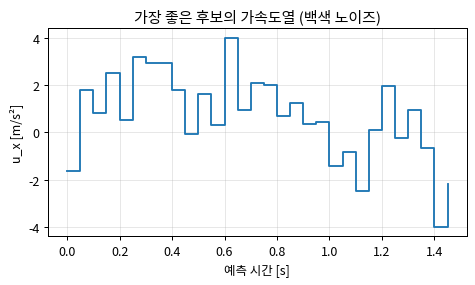

In [2]:
p0, v0 = np.zeros(2), np.zeros(2)
cost0 = lambda U: point_cost(*point_rollout(p0, v0, U, DT2), U, goal, obstacles)
jerk = lambda us: np.abs(np.diff(us, axis=0)).mean()

_, _, info_w = mppi_step(np.zeros((T, 2)), 2.0, cost0, K, 1.0, np.random.default_rng(0), u_max=4.0)
print('백색 노이즈: 가장 좋은 후보의 가속도 변화량 평균 %.2f m/s²' % jerk(info_w['best']))

plt.figure(figsize=(6, 3))
plt.step(np.arange(T) * DT2, info_w['best'][:, 0], where='post')
plt.xlabel('예측 시간 [s]'); plt.ylabel('u_x [m/s²]'); plt.title('가장 좋은 후보의 가속도열 (백색 노이즈)')
plt.show()

### 해결
노이즈를 시점마다 따로 뽑지 않는다. horizon 전체에서 **점 몇 개(knot)만** 무작위로 뽑고, 그 사이를 매끄러운 곡선(3차 스플라인)으로 잇는다. 그러면 후보 하나하나가 부드럽게 변하는 가속도열이 된다.

**예측해 보기:** 같은 방식으로 한 번 갱신했을 때, 가장 좋은 후보의 가속도 변화량은 얼마나 줄어들까?

knot 노이즈: 가장 좋은 후보의 가속도 변화량 평균 0.40 m/s²


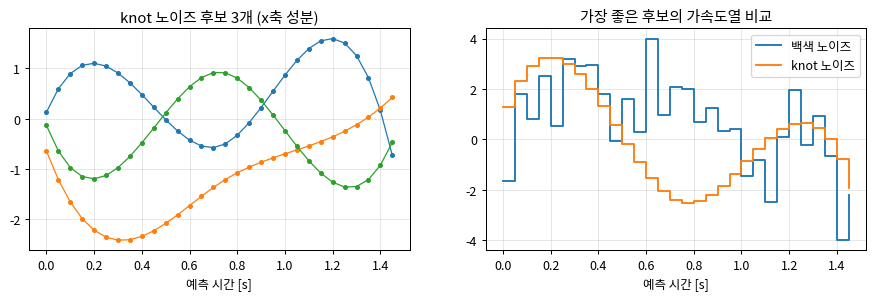

In [3]:
def knot_noise(K, T, d, n_knots=5, rng=None):
    knots = rng.standard_normal((K, n_knots, d))                       # 시점 5개만 무작위
    spline = make_interp_spline(np.linspace(0, 1, n_knots), knots, k=3, axis=1)
    z = spline(np.linspace(0, 1, T))                                    # T개 시점으로 매끄럽게 잇기
    return z / z.std()                                                  # 표준편차를 1로 맞춤

noise_k = knot_noise(K, T, 2, rng=np.random.default_rng(0))
_, _, info_k = mppi_step(np.zeros((T, 2)), 2.0, cost0, K, 1.0, np.random.default_rng(0), u_max=4.0, noise=noise_k)
print('knot 노이즈: 가장 좋은 후보의 가속도 변화량 평균 %.2f m/s²' % jerk(info_k['best']))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
for i in range(3):
    axs[0].plot(np.arange(T) * DT2, noise_k[i, :, 0], '.-', lw=1)
axs[0].set_title('knot 노이즈 후보 3개 (x축 성분)'); axs[0].set_xlabel('예측 시간 [s]')
axs[1].step(np.arange(T) * DT2, info_w['best'][:, 0], where='post', label='백색 노이즈')
axs[1].step(np.arange(T) * DT2, info_k['best'][:, 0], where='post', label='knot 노이즈')
axs[1].legend(); axs[1].set_title('가장 좋은 후보의 가속도열 비교'); axs[1].set_xlabel('예측 시간 [s]')
plt.show()

**결과 해석:** knot 노이즈로 만든 가장 좋은 후보는 가속도가 매끄럽게 변하고, 변화량이 몇 배 작다.

MPC 루프에서 **실제로 실행된 명령**도 비교해 보자. 실행된 명령은 매 스텝 그때그때 가장 좋은 후보의 **첫 값**이다. 그래서 후보 하나 안이 매끄러워도, 스텝마다 다른 후보가 뽑히면 스텝 사이 명령은 여전히 바뀔 수 있다.

백색   노이즈: 실행된 명령 변화량 평균 2.16 m/s², 도착 1.4 s
knot 노이즈: 실행된 명령 변화량 평균 1.60 m/s², 도착 1.3 s


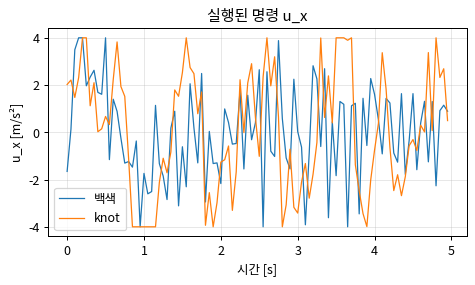

In [4]:
rng_n = np.random.default_rng(1)
r_white = mppi_mpc_2d(goal, obstacles, use_best=True, steps=100)
r_knot = mppi_mpc_2d(goal, obstacles, use_best=True, steps=100, noise_fn=lambda s, i: knot_noise(K, T, 2, rng=rng_n))
for name, r in [('백색', r_white), ('knot', r_knot)]:
    print('%-4s 노이즈: 실행된 명령 변화량 평균 %.2f m/s², 도착 %s s' % (name, jerk(r['us']), arrival_time(r['traj'], goal)))

plt.figure(figsize=(6, 3))
for name, r in [('백색', r_white), ('knot', r_knot)]:
    plt.plot(np.arange(100) * DT2, r['us'][:, 0], lw=1, label=name)
plt.legend(); plt.xlabel('시간 [s]'); plt.ylabel('u_x [m/s²]'); plt.title('실행된 명령 u_x')
plt.show()

**결과 해석:** 실행된 명령 기준으로도 knot 노이즈 쪽이 덜 떨리지만, 차이는 계획 안에서 본 것보다 작다. 이 차이와 도착 시간은 seed에 따라 앞뒤로 달라져서, 이 실행 한 번만으로 일정한 효과라고 말하기는 어렵다. 분명한 효과는 **선택된 계획 자체가 매끄러워진다**는 점이다.

knot 개수가 적으면 짧은 시간 안에 방향을 크게 바꾸는 계획을 표현하기 어렵다. 그래서 cuRobo는 두 종류를 섞어 쓴다.

**이름:** 이 방식을 **knot 샘플링**이라 부르고, knot 개수가 `n_knots`다. `course.smooth_noise`에 같은 코드가 있다. cuRobo는 후보의 30%를 시점별 노이즈, 70%를 knot 노이즈로 만든다(`sample_ratio`).

## 2. 고르지 않은 샘플 → Halton 준난수

### 문제
후보를 수백 개 뽑아도 무작위 샘플은 생각보다 고르게 퍼지지 않는다. 우연히 몰린 곳과 비어 있는 곳이 생긴다. 비어 있는 방향에 좋은 해가 있으면 놓친다.

### 실패 데모
정사각형 안에 점 64개를 무작위로 찍어 본다. 퍼진 정도를 숫자로 보려고 **불균일도**(discrepancy)를 계산한다. 값이 작을수록 고르게 퍼진 것이다.

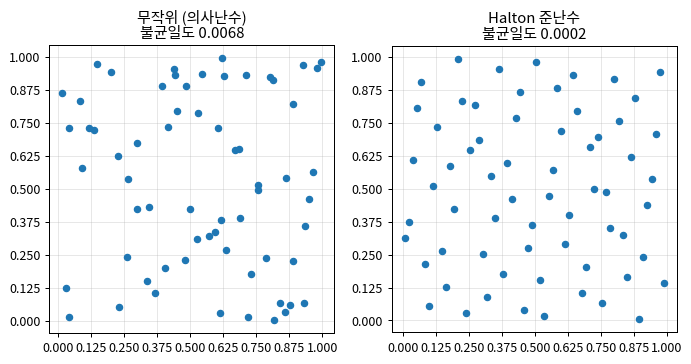

In [5]:
pts_random = np.random.default_rng(0).random((64, 2))
pts_halton = qmc.Halton(d=2, scramble=True, seed=0).random(64)
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, pts, name in [(axs[0], pts_random, '무작위 (의사난수)'), (axs[1], pts_halton, 'Halton 준난수')]:
    ax.plot(*pts.T, 'o', ms=5)
    ax.set_xticks(np.linspace(0, 1, 9)); ax.set_yticks(np.linspace(0, 1, 9)); ax.set_aspect('equal')
    ax.set_title('%s\n불균일도 %.4f' % (name, qmc.discrepancy(pts)))
plt.show()

**결과 해석:** 무작위 점은 몰린 칸과 빈 칸이 눈에 띈다. Halton 점은 격자 칸마다 거의 고르게 들어가고, 불균일도도 훨씬 작다.

### 해결
**준난수**(quasi-random number)는 앞에서 찍은 점들 사이의 빈 곳을 차례로 채우도록 만든 수열이다. 무작위처럼 보이지만 공간을 더 고르게 덮는다. 그중 하나가 **Halton 수열**이다.

MPPI 노이즈는 0~1 사이 값이 아니라 정규분포 값이어야 한다. 그래서 0~1 사이의 Halton 값을 정규분포의 **역누적분포 함수**(`norm.ppf`)에 넣어 변환한다. 0.5는 0으로, 0.84는 약 +1로, 0.16은 약 −1로 바뀐다.

In [6]:
u = qmc.Halton(d=1, scramble=True, seed=0).random(400)[:, 0]
z = norm.ppf(u)
print('Halton 값 예: %s → 정규분포 값: %s' % (u[:4].round(3), z[:4].round(2)))
print('변환 후 평균 %.3f, 표준편차 %.3f' % (z.mean(), z.std()))

Halton 값 예: [0.099 0.599 0.349 0.849] → 정규분포 값: [-1.29  0.25 -0.39  1.03]
변환 후 평균 0.006, 표준편차 0.999


**이름:** cuRobo의 `sample_ratio: {'halton': 0.3, 'halton-knot': 0.7}`는 "30%는 시점별 Halton 노이즈, 70%는 Halton으로 knot 값을 뽑은 매끄러운 노이즈"라는 뜻이다. 1절과 이 절을 합친 것이다. `course.smooth_noise(..., halton=True)`가 knot 값을 Halton으로 뽑는다.

## 3. 실행할 때마다 다른 결과 → 고정 샘플

### 문제
이 프로젝트는 "손 비용의 η를 25 mm로 할 때와 73.5 mm로 할 때"를 비교한다. 그런데 MPPI는 무작위 샘플을 쓰므로, 같은 조건으로 다시 실행해도 결과가 조금씩 달라진다. 두 조건의 결과가 다를 때, 그 차이가 η 때문인지 샘플 운 때문인지 구분하기 어렵다.

### 실패 데모
같은 조건에서 난수 seed만 바꿔 세 번 실행한다.

seed 0: 가장 높이 올라간 y = 0.3161 m, 도착 1.7 s
seed 1: 가장 높이 올라간 y = 0.3163 m, 도착 1.95 s
seed 2: 가장 높이 올라간 y = 0.3211 m, 도착 1.7 s


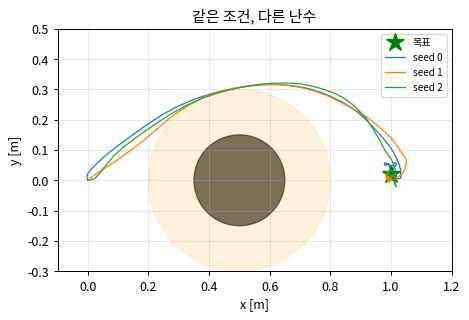

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
plot_scene_2d(ax, goal, obstacles, eta=0.1, lim=((-0.1, 1.2), (-0.3, 0.5)))
for seed in [0, 1, 2]:
    r = mppi_mpc_2d(goal, obstacles, seed=seed, steps=100)
    ax.plot(*r['traj'].T, lw=1, label=f'seed {seed}')
    print('seed %d: 가장 높이 올라간 y = %.4f m, 도착 %s s' % (seed, r['traj'][:, 1].max(), arrival_time(r['traj'], goal)))
ax.legend(fontsize=8); ax.set_title('같은 조건, 다른 난수'); plt.show()

### 해결
노이즈 묶음을 **처음에 한 번만 만들고**, 모든 스텝·모든 반복에서 같은 묶음을 다시 쓴다. 그러면 같은 조건은 항상 같은 결과를 낸다. 조건을 바꿨을 때 달라지는 것은 비용뿐이다.

In [8]:
fixed = smooth_noise(K, T, 2, seed=0)                     # 한 번만 만든 노이즈 묶음
run = lambda eta: mppi_mpc_2d(goal, obstacles, eta=eta, steps=100, noise_fn=lambda s, i: fixed)
a, b = run(0.1), run(0.1)
print('같은 조건 두 번 실행, 경로가 완전히 같은가:', np.array_equal(a['traj'], b['traj']))
for eta in [0.05, 0.15]:
    r = run(eta)
    gap = np.linalg.norm(r['traj'] - obstacles[0][0], axis=1) - obstacles[0][1] - 0.05
    print('η = %.2f m: 최소 간격 %.3f m, 도착 %s s' % (eta, gap.min(), arrival_time(r['traj'], goal)))

같은 조건 두 번 실행, 경로가 완전히 같은가: True
η = 0.05 m: 최소 간격 0.073 m, 도착 2.05 s
η = 0.15 m: 최소 간격 0.165 m, 도착 1.85 s


**결과 해석:** 고정 샘플을 쓰면 같은 조건의 결과가 완전히 같다. η를 바꾸면 최소 간격이 η를 따라 바뀐다. 이 차이는 샘플 운이 아니라 비용 설정에서 나온 것이다.

솔직하게 덧붙이면, 난수 seed를 고정해도 재현성은 얻을 수 있다. 고정 샘플의 다른 장점은 노이즈를 매번 새로 만들 필요가 없어 계산이 가볍다는 점이다. cuRobo처럼 GPU 계산을 미리 녹화해 두고 다시 재생(CUDA graph)하는 구조에서는 특히 그렇다. 대가도 있다. 매 스텝 같은 노이즈 모양만 쓰니 탐색이 덜 다양하고, 결과는 "이 노이즈 묶음 하나"에 대한 것이다. 그래서 결론을 일반화하려면 여러 seed로 반복 실험해야 한다.

**이름:** cuRobo `sample_params.fixed_samples: True`.

## 4. 평균이 틀렸을 때 → 0 입력 후보, −평균 후보

### 문제
MPPI 후보는 모두 평균 주변에서 뽑는다. 그런데 평균이 크게 틀렸다면? 예를 들어 오른쪽 목표를 향해 가속하던 중에 목표가 갑자기 뒤쪽으로 바뀌면, warm start로 이어받은 평균은 여전히 "오른쪽으로 가속"이다. 탐색 폭 σ가 좁으면 후보 전부가 틀린 쪽에 몰린다.

### 실패 데모
오른쪽으로 1.5 m/s로 달리고 있고, 평균은 "오른쪽으로 3 m/s² 가속"이며, 목표는 원점(뒤쪽)이다. σ = 0.3으로 좁게 둔다. MPPI를 5번 갱신하며 가장 좋은 후보의 비용을 기록한다.

0 후보  0, -평균 후보  0: 반복별 최저 비용 [1044.   987.   914.6  851.8  763. ], 첫 명령 u_x = +2.04
0 후보 10, -평균 후보 10: 반복별 최저 비용 [29.7 25.5 23.8 22.3 21.8], 첫 명령 u_x = -2.84


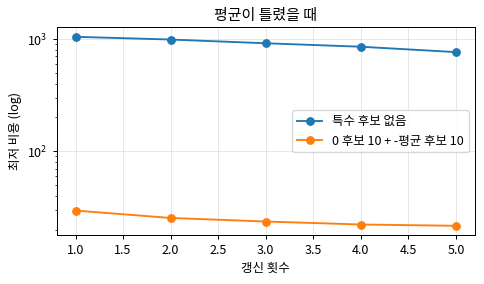

In [9]:
p_s, v_s = np.array([0.5, 0.0]), np.array([1.5, 0.0])
mu_wrong = np.tile([3.0, 0.0], (T, 1))
cost_s = lambda U: point_cost(*point_rollout(p_s, v_s, U, DT2), U, [0.0, 0.0], [])

results = {}
for n_zero, n_neg in [(0, 0), (10, 10)]:
    rng = np.random.default_rng(0); mu = mu_wrong.copy(); best_J = []
    for it in range(5):
        mu, _, info = mppi_step(mu, 0.3, cost_s, K, 1.0, rng, u_max=4.0, n_zero=n_zero, n_neg=n_neg)
        best_J.append(info['J'].min())
    results[(n_zero, n_neg)] = best_J
    print('0 후보 %2d, -평균 후보 %2d: 반복별 최저 비용 %s, 첫 명령 u_x = %+.2f' % (n_zero, n_neg, np.round(best_J, 1), mu[0, 0]))

plt.figure(figsize=(6, 3))
for key, J in results.items():
    plt.semilogy(range(1, 6), J, 'o-', label='특수 후보 없음' if key == (0, 0) else '0 후보 10 + -평균 후보 10')
plt.xlabel('갱신 횟수'); plt.ylabel('최저 비용 (log)'); plt.legend(); plt.title('평균이 틀렸을 때'); plt.show()

**결과 해석:** 특수 후보가 없으면 모든 후보가 "오른쪽 가속" 주변에 있어서 5번 갱신해도 비용이 천천히 줄어든다. 첫 명령도 여전히 오른쪽 가속(+)이다. −평균 후보(왼쪽 3 m/s²)를 넣으면 첫 갱신부터 비용이 수십 배 낮은 후보를 찾고, 첫 명령이 바로 감속(−)으로 바뀐다.

### 해결과 이름
후보 몇 개는 평균과 상관없이 따로 넣는다.
- **0 입력 후보**: 가속도 0, 즉 지금 속도 유지. 평균이 쓸데없이 움직이고 있을 때를 대비한다.
- **−평균 후보**: 평균과 정반대로 가속한다. 평균 방향이 틀렸을 때를 대비한다.

cuRobo는 `null_act_frac: 0.05`, 즉 400개의 5%인 20개를 이렇게 쓴다. 절반(10개)은 0 입력, 나머지 절반(10개)은 −평균이다. 또 노이즈 하나를 0으로 두어 **평균 자체도 후보**에 들어가게 한다. 나머지 380개가 평균 + 노이즈다.

## 5. 탐색 폭 σ → 천천히 갱신하기

### 문제
지금까지 σ는 고정값이었다. σ가 작으면 멀리 있는 다른 길을 못 찾고, 크면 목표 근처에서 정밀하게 맞추기 어렵다. 좋은 후보들이 퍼진 정도를 보고 σ를 자동으로 조절하면 어떨까?

### 아이디어
평균을 가중평균으로 옮기듯이, σ²도 "좋은 후보들이 평균에서 얼마나 퍼져 있는지"(가중 분산)를 향해 옮긴다. 다만 한 번에 다 옮기지 않고 일부만 반영한다.

$$
\mu \leftarrow (1-\alpha_\mu)\,\mu + \alpha_\mu\sum_k \omega_k U_k,\qquad
\sigma^2 \leftarrow (1-\alpha_\sigma)\,\sigma^2 + \alpha_\sigma \underbrace{\textstyle\sum_k \omega_k (U_k-\mu)^2}_{\text{가중 분산 (시점 평균)}} + \kappa
$$

말로 하면, $\alpha_\mu$와 $\alpha_\sigma$는 "새 정보를 얼마나 반영할지"이고, $\kappa$는 분산이 0이 되지 않게 하는 바닥값이다. `mppi_step`의 `step_size_mean`, `step_size_cov`, `kappa` 옵션이 이 식이다.

**예측해 보기:** 06의 넓은 벽 장면(T = 40)에서 $\alpha_\sigma$를 0(고정), 0.01(천천히), 0.5(빠르게)로 하면 어느 것이 실패할까?

α_σ = 0.00: 10초 뒤 목표 오차 0.029 m, 마지막 σ = [2. 2.]
α_σ = 0.01: 10초 뒤 목표 오차 0.025 m, 마지막 σ = [1.767 1.763]
α_σ = 0.50: 10초 뒤 목표 오차 0.142 m, 마지막 σ = [0.394 0.415]


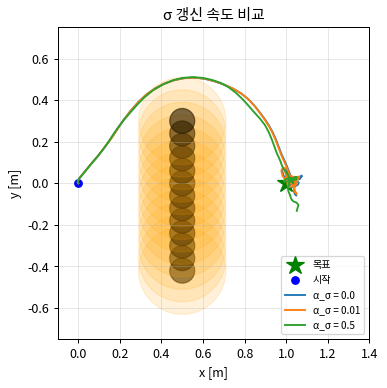

In [10]:
wall = [([0.5, y], 0.06) for y in np.arange(-0.42, 0.31, 0.06)]
goal_w = np.array([1.0, 0.0])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
plot_scene_2d(ax, goal_w, wall, eta=0.1, start=(0, 0), lim=((-0.1, 1.4), (-0.75, 0.75)))
for ssc in [0.0, 0.01, 0.5]:
    r = mppi_mpc_2d(goal_w, wall, T=40, sigma=2.0, steps=200, step_size_mean=0.9,
                    step_size_cov=ssc, kappa=1e-4 if ssc else 0.0)
    err = np.linalg.norm(r['traj'][-1] - goal_w)
    print('α_σ = %.2f: 10초 뒤 목표 오차 %.3f m, 마지막 σ = %s' % (ssc, err, r['sigma'].round(3)))
    ax.plot(*r['traj'].T, label=f'α_σ = {ssc}')
ax.legend(fontsize=8, loc='lower right'); ax.set_title('σ 갱신 속도 비교'); plt.show()

**결과 해석:** 세 경우 모두 벽은 돌아간다. σ를 고정하거나 천천히(0.01) 갱신하면 목표에 자리를 잡는다. 빠르게(0.5) 갱신하면 σ가 처음의 5분의 1인 0.4 근처까지 줄어들고, 목표 근처에서 자리를 잡지 못한 채 약 0.14 m 떨어져 끝난다. 원인을 이 실험 하나로 단정하기는 어렵다. 다만 σ가 빠르게 줄면 그 뒤로는 평균 바로 근처의 후보만 시험하게 되어, 계획이 한번 어긋나면 바로잡을 후보가 부족해진다.

이 장면에서는 σ를 고정해도 잘 됐다. σ 갱신에는 득과 실이 함께 있다. 천천히 갱신하면 상황에 맞게 탐색 폭이 조절되고, 빠르게 갱신하면 탐색 폭이 너무 일찍 줄어드는(붕괴하는) 위험이 커진다. cuRobo가 평균은 빠르게(0.9), 분산은 아주 천천히(0.01) 갱신하는 이유다.

**직접 해보기:** α_σ = 0.5를 그대로 두고 `kappa`만 1e-4에서 0.01로 키워 보자. 바닥값이 커지면 무엇이 달라질까?
<details><summary>실행 결과</summary>

σ가 약 0.9 아래로 내려가지 않고, 목표 오차가 약 0.14 m에서 약 0.035 m로 줄어든다. κ는 σ²에 매번 더해지는 바닥값이라, 분산 갱신이 빨라도 탐색 폭이 완전히 무너지지 않게 붙잡아 준다. 대신 κ가 너무 크면 목표 근처에서도 후보가 넓게 퍼져 미세 조정이 거칠어진다.
</details>

**이름:** `step_size_mean: 0.9`, `step_size_cov: 0.01`, `kappa: 0.0001`. 처음 분산은 `init_cov: 0.05`(표준편차 약 0.22)다. 관절마다 분산을 따로 두는 방식이 `cov_type: 'DIAG_A'`다.

## 6. 물리 한계를 넘는 후보 → 자르기(clamp)

### 문제
노이즈를 더하다 보면 실제 모터가 낼 수 없는 큰 가속도를 가진 후보가 생긴다. 그런 후보로 rollout하면 "불가능한 미래"를 계산하게 되고, 그 후보가 선택되면 실제 로봇은 계획대로 움직일 수 없다.

### 실패 데모
가속도 한계는 4 m/s²인데, 자르지 않고(σ = 4) MPPI를 돌려 본다.

자르지 않음  : 후보 가속도 최대 |u| = 29.6, 계획(평균) 최대 |u| = 15.6 m/s²
±4로 자름  : 후보 가속도 최대 |u| = 4.0, 계획(평균) 최대 |u| = 3.6 m/s²


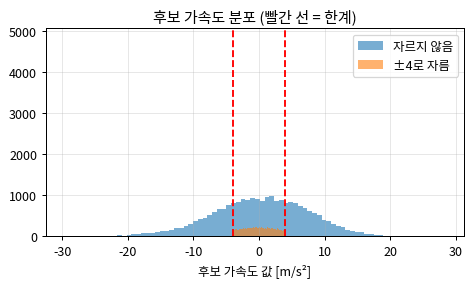

In [11]:
fig, ax = plt.subplots(figsize=(6, 3))  # p0, v0, cost0은 1절에서 정의
for u_max, name in [(None, '자르지 않음'), (4.0, '±4로 자름')]:
    rng = np.random.default_rng(0); mu = np.zeros((T, 2))
    for it in range(5):
        mu, _, info = mppi_step(mu, 4.0, cost0, K, 1.0, rng, u_max=u_max)
    print('%-8s: 후보 가속도 최대 |u| = %.1f, 계획(평균) 최대 |u| = %.1f m/s²' % (name, np.abs(info['U']).max(), np.abs(mu).max()))
    ax.hist(info['U'].ravel(), bins=80, alpha=0.6, label=name)
ax.axvline(4, color='r', ls='--'); ax.axvline(-4, color='r', ls='--')
ax.set_xlabel('후보 가속도 값 [m/s²]'); ax.legend(); ax.set_title('후보 가속도 분포 (빨간 선 = 한계)'); plt.show()

**결과 해석:** 자르지 않으면 후보에 한계의 몇 배나 되는 가속도가 생기고, 계획(평균)도 한계를 훌쩍 넘는다. 실제 모터로는 따라갈 수 없는 계획이다. rollout 전에 후보를 한계 안으로 잘라 두면, 모든 후보가 물리적으로 가능한 미래만 계산하게 된다.

**이름:** cuRobo `squash_fn: 'CLAMP'`. 관절 가속도 한계로 후보를 자른다.

## 7. 반복을 몇 번 할까 → 계산 시간과의 절충

### 문제
05에서 MPPI 갱신을 여러 번 반복하면 평균이 점점 좋아졌다. 그런데 로봇은 1초에 60번(약 16.7 ms마다) 명령을 내야 한다. 반복은 몇 번까지 할 수 있을까?

### 실패 데모
같은 상태에서 반복 횟수를 바꾸며 평균 계획의 비용과 걸린 시간을 잰다.

반복  1번: 평균 계획 비용 20.20, 걸린 시간 1.8 ms
반복  2번: 평균 계획 비용 17.19, 걸린 시간 3.5 ms
반복  5번: 평균 계획 비용 13.33, 걸린 시간 8.4 ms
반복 10번: 평균 계획 비용 11.95, 걸린 시간 16.7 ms
반복 20번: 평균 계획 비용 10.74, 걸린 시간 33.6 ms


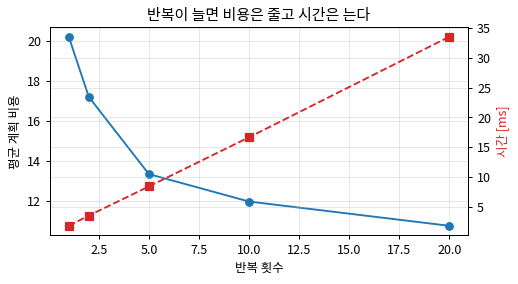

In [12]:
iters_list, costs, times = [1, 2, 5, 10, 20], [], []
for n in iters_list:
    rng = np.random.default_rng(0); mu = np.zeros((T, 2)); t0 = time.perf_counter()
    for it in range(n):
        mu, _, _ = mppi_step(mu, 2.0, cost0, K, 1.0, rng, u_max=4.0)
    times.append(1000 * (time.perf_counter() - t0)); costs.append(cost0(mu[None])[0])
    print('반복 %2d번: 평균 계획 비용 %.2f, 걸린 시간 %.1f ms' % (n, costs[-1], times[-1]))
fig, ax1 = plt.subplots(figsize=(6, 3))
ax1.plot(iters_list, costs, 'o-'); ax1.set_xlabel('반복 횟수'); ax1.set_ylabel('평균 계획 비용')
ax2 = ax1.twinx(); ax2.plot(iters_list, times, 's--', color='tab:red'); ax2.set_ylabel('시간 [ms]', color='tab:red')
ax1.set_title('반복이 늘면 비용은 줄고 시간은 는다'); plt.show()

**결과 해석:** 반복할수록 비용은 줄지만, 줄어드는 폭은 점점 작아지고 시간은 반복 횟수에 비례해 늘어난다. 이 numpy 구현은 CPU에서 돌아서 느리다. GPU에서 돌리는 cuRobo는 후보 400개 × 7관절로 5번 반복해도 MPC 한 번에 약 10 ms 안팎이 걸린다(12 노트에서 실제 로그로 확인). 60 Hz 제어에 맞추려면 반복 횟수를 작게 고정해야 한다. 대신 warm start(06)로 지난 스텝의 결과를 이어받아 반복이 적은 것을 보완한다.

**이름:** cuRobo `n_iters: 5`.

## 8. cuRobo 설정 파일 읽기

이제 cuRobo의 MPPI 설정 파일을 직접 열어 보자. 지금까지 배운 장치가 모두 들어 있다.

In [13]:
cfg = load_yaml(CUROBO / 'src/curobo/content/configs/task/particle_mpc.yml')['mppi']
for key in ['num_particles', 'n_iters', 'init_cov', 'gamma', 'beta', 'step_size_mean', 'step_size_cov',
            'kappa', 'null_act_frac', 'cov_type', 'sample_mode', 'squash_fn', 'base_action']:
    print(f'{key:15s} {cfg[key]}')
sp = cfg['sample_params']
print('sample_params   fixed_samples=%s, n_knots=%s, sample_ratio=%s' % (sp['fixed_samples'], sp['n_knots'], sp['sample_ratio']))
n_null = round(int(cfg['null_act_frac'] * cfg['num_particles'] * 0.5))
n_neg = round(int(cfg['null_act_frac'] * cfg['num_particles'])) - n_null
print('→ 후보 구성: 평균+노이즈 %d개, 0 입력 %d개, -평균 %d개' % (cfg['num_particles'] - n_null - n_neg, n_null, n_neg))

num_particles   400
n_iters         5
init_cov        0.05
gamma           0.98
beta            0.1
step_size_mean  0.9
step_size_cov   0.01
kappa           0.0001
null_act_frac   0.05
cov_type        DIAG_A
sample_mode     BEST
squash_fn       CLAMP
base_action     REPEAT
sample_params   fixed_samples=True, n_knots=5, sample_ratio={'halton': 0.3, 'halton-knot': 0.7, 'random': 0.0, 'random-knot': 0.0}
→ 후보 구성: 평균+노이즈 380개, 0 입력 10개, -평균 10개


| 설정 이름 | 값 | 푸는 문제 | 배운 곳 |
|---|---|---|---|
| `num_particles` | 400 | 후보 개수 | 05 |
| `beta` | 0.1 | 비용 → 가중치의 온도 (비용 크기와 비교해서 해석) | 05 |
| `gamma` | 0.98 | 먼 미래 비용 할인 | 06 4절 |
| `sample_mode` | `BEST` | 두 무리 평균 문제 → 가장 좋은 후보로 명령 | 06 6절 |
| `base_action` | `REPEAT` | warm start에서 한 칸 당긴 뒤 마지막 칸을 반복해서 채움 | 06 5절 |
| `sample_ratio`, `n_knots` | halton 0.3 / halton-knot 0.7, 5 | 명령 떨림 → 매끄러운 노이즈, 고르지 않은 샘플 → Halton | 07 1·2절 |
| `fixed_samples` | True | 재현성, 계산 절약 | 07 3절 |
| `null_act_frac` | 0.05 | 평균이 틀렸을 때 → 0 입력 10개 + −평균 10개 | 07 4절 |
| `init_cov`, `step_size_cov`, `kappa`, `cov_type` | 0.05, 0.01, 1e-4, DIAG_A | 탐색 폭을 천천히 조절, 붕괴 방지 | 07 5절 |
| `step_size_mean` | 0.9 | 평균은 빠르게 이동 | 07 5절 |
| `squash_fn` | CLAMP | 물리 한계를 넘는 후보 자르기 | 07 6절 |
| `n_iters` | 5 | 계산 시간 안에서 반복 | 07 7절 |

## 핵심 정리

- 가장 좋은 후보를 명령으로 쓰면 노이즈 모양이 명령에 그대로 들어간다. 그래서 **knot 기반 매끄러운 노이즈**를 섞는다. knot이 적으면 급한 방향 전환을 표현하기 어려워서 시점별 노이즈와 함께 쓴다.
- **Halton 준난수**는 같은 개수로 공간을 더 고르게 덮는다.
- **고정 샘플**은 재현성과 계산 절약을 준다. 결론을 일반화하려면 여러 seed 반복이 따로 필요하다.
- 평균이 틀렸을 때를 대비해 **0 입력·−평균 후보**를 넣는다.
- σ는 **천천히** 갱신하고(κ로 바닥값), 후보는 물리 한계로 **자르고(clamp)**, 반복은 시간 예산 안에서 **고정 횟수**만 한다.

## 확인 문제

<details><summary>1. 가중평균을 명령으로 쓸 때보다 가장 좋은 후보를 쓸 때 노이즈의 매끄러움이 더 중요한 이유는?</summary>

가중평균은 여러 후보를 평균하면서 노이즈의 들쭉날쭉함이 상쇄된다. 단일 후보는 그 후보의 노이즈가 명령에 그대로 들어간다.
</details>

<details><summary>2. knot 노이즈로 계획 안의 떨림은 크게 줄었는데, 실행된 명령의 떨림은 덜 줄어든 이유는?</summary>

실행된 명령은 매 스텝 그때 가장 좋은 후보의 첫 값이다. 스텝마다 다른 후보가 선택되면, 후보 하나 안이 매끄러워도 스텝 사이 명령은 바뀔 수 있다.
</details>

<details><summary>3. cuRobo의 후보 400개는 어떻게 구성되나?</summary>

평균 + 노이즈 380개(그중 하나는 노이즈 0, 즉 평균 자체), 0 입력 10개, −평균 10개.
</details>

<details><summary>4. step_size_cov를 0.5로 키우면 어떤 위험이 있나?</summary>

σ가 몇 스텝 만에 크게 줄어 탐색 폭이 일찍 무너진다. 그 뒤로는 평균 바로 근처의 후보만 시험하므로, 계획이 어긋났을 때 바로잡을 후보가 부족하다. 5절 벽 장면에서는 목표 근처에서 자리를 잡지 못했다.
</details>

<details><summary>5. fixed_samples=True로 R/LOW/HIGH 조건을 비교한 결과를 일반화할 때 주의할 점은?</summary>

결과가 노이즈 묶음 하나에 대한 것이다. 조건 간 차이가 비용에서 온다고 해석하기는 쉽지만, 다른 노이즈 묶음(seed)에서도 같은 경향이 나오는지는 반복 실험으로 따로 확인해야 한다.
</details>

## 실제 프로젝트에서는

모든 위치는 `~/curobo/src/curobo/` 기준이다.

| 장치 | 코드 위치 |
|---|---|
| 후보 생성: 평균 + 노이즈·σ, −평균, 0 입력, CLAMP | `opt/particle/parallel_mppi.py:329-363` (`sample_actions`) |
| 노이즈 하나를 0으로 (평균 자체를 후보로) | `opt/particle/parallel_mppi.py:582` |
| 0 입력·−평균 후보 개수 계산 | `opt/particle/particle_opt_base.py:286-289` |
| 가장 좋은 후보 저장 (BEST) | `opt/particle/parallel_mppi.py:295-298` |
| 평균·분산 갱신 (`step_size_mean`, `step_size_cov`, `kappa`) | `opt/particle/parallel_mppi.py:650-679` |
| 설정 파일 | `content/configs/task/particle_mpc.yml` |

franka-depth-mppi는 이 설정을 바꾸지 않고 그대로 썼다. 바꾼 것은 비용(손 전용 충돌 비용)뿐이다(11 노트).

## 다음 노트

[08 · 점에서 로봇팔로](08_robot_arm.ipynb): 지금까지는 점 하나를 움직였다. 로봇팔은 관절 각도를 움직이고, 몸 전체가 장애물을 피해야 한다. 관절 공간, 순기구학, 충돌 구를 배우고 같은 MPPI로 2관절 팔을 움직여 본다.